# Carga dos Dados

In [1]:
import kagglehub
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


caminho_pasta = kagglehub.dataset_download("yashdev01/spotify-tracks-dataset")
print("Os arquivos foram baixados em:", caminho_pasta)
try:
  df = pd.read_csv(os.path.join(caminho_pasta, "spotify-tracks-dataset.csv"))
except FileNotFoundError:
  print("Erro ao carregar o arquivo CSV")
else:
  print("Importação concluída")

c:\Users\beatr\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 8.42M/8.42M [00:01<00:00, 6.64MB/s]

Extracting files...


Os arquivos foram baixados em: C:\Users\beatr\.cache\kagglehub\datasets\yashdev01\spotify-tracks-dataset\versions\1
Importação concluída


Usamos o dataset Spotify Tracks, disponível no Kaggle (https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset). Cada linha é uma faixa e as colunas trazem a popularidade (de 0 a 100), características de áudio calculadas pelo Spotify (danceability, energy, loudness, speechiness, acousticness, instrumentalness, liveness, valence, tempo e duração) e algumas variáveis categóricas (explicit, key, mode, time_signature e o gênero da faixa). A descrição do Kaggle fala em 125 gêneros, mas o arquivo tem 114.

O problema de regressão é explicar a popularidade de uma faixa a partir dessas características.

## Limpeza Inicial

In [2]:
print(df.shape)
df.info()

print(f'\nMissing values:\n{df.isnull().sum()[df.isnull().sum() > 0]}')
print(f'\nDuplicate values:\n{df.duplicated().sum()}')

df.drop(columns=[c for c in df.columns if 'Unnamed' in c], inplace=True)

print(f'\nDuplicate values after cleaning:\n{df.duplicated().sum()}')

df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
print(f'\nShape sem duplicatas exatas: {df.shape}')
print(f'track_id repetidos em mais de um gênero: {df.duplicated(subset="track_id").sum()}')

print(f'\nFaixas com duração <= 0: {(df["duration_ms"] <= 0).sum()}')
df = df[df['duration_ms'] > 0].reset_index(drop=True)

print(f'Faixas com compasso 0/4: {(df["time_signature"] == 0).sum()}')
df = df[df['time_signature'] != 0].reset_index(drop=True)

df_genero = df[['track_genre', 'popularity']].copy()

df.drop_duplicates(subset='track_id', inplace=True)
df.drop(columns=['track_id', 'artists', 'album_name', 'track_name', 'track_genre'], inplace=True)
df.reset_index(drop=True, inplace=True)
print(f'Shape final: {df.shape}')

(114000, 22)
<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 22 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0.1      114000 non-null  int64  
 1   Unnamed: 0        114000 non-null  int64  
 2   track_id          114000 non-null  str    
 3   artists           113999 non-null  str    
 4   album_name        113999 non-null  str    
 5   track_name        113999 non-null  str    
 6   popularity        114000 non-null  int64  
 7   duration_ms       114000 non-null  int64  
 8   explicit          114000 non-null  bool   
 9   danceability      114000 non-null  float64
 10  energy            114000 non-null  float64
 11  key               114000 non-null  int64  
 12  loudness          114000 non-null  float64
 13  mode              114000 non-null  int64  
 14  speechiness       114000 non-null  float64
 15  acousticness      114000 non-null  float64
 16  instrumentalness  

In [3]:
key_names = ['C', 'C♯/D♭', 'D', 'D♯/E♭', 'E', 'F', 'F♯/G♭', 'G', 'G♯/A♭', 'A', 'A♯/B♭', 'B']

df['duration_min'] = df['duration_ms'] / 60000
df['nota'] = df['key'].map(lambda x: key_names[x] if 0 <= x <= 11 else 'Desconhecida')
df['modo'] = df['mode'].map({0: 'Menor', 1: 'Maior'})
df['explicita'] = df['explicit'].map({False: 'Não explícita', True: 'Explícita'})
df['compasso'] = df['time_signature'].map(lambda x: f'{x}/4')

caract_tec = [
    'danceability','energy','loudness','speechiness','acousticness',
    'instrumentalness','liveness','valence','tempo','duration_min'
]

Retiramos as colunas de índice (Unnamed) e 450 linhas totalmente duplicadas. Também saíram uma faixa com duração de 0 ms e as faixas com compasso 0/4, que não existe musicalmente e indica falha na análise do Spotify. As faixas com tempo igual a 0 foram mantidas. O único valor faltante estava em colunas descritivas (artists, album_name e track_name), que são descartadas de qualquer forma.

O track_id aparece repetido em 23.809 linhas, porque a mesma faixa pode estar listada em mais de um gênero. Faixas repetidas violam a independência dos erros da regressão, então o dataframe `df` ficou com uma linha por track_id. Como o gênero de uma faixa repetida seria arbitrário (a primeira ocorrência), a coluna track_genre saiu do `df` e as análises de gênero usam o `df_genero`, que mantém uma linha para cada gênero em que a faixa aparece. Por fim, retiramos track_id, artists, album_name e track_name, que são campos identificadores.

Depois disso, convertemos a duração para minutos (duration_min) e trocamos os códigos de key, mode, explicit e time_signature pelos nomes das categorias.

# Exploração dos Dados

## Popularidade

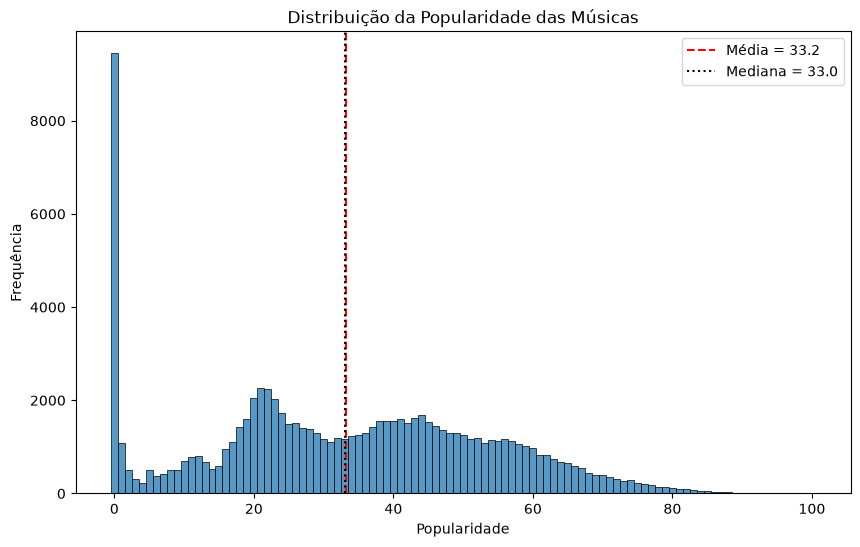

count    89578.000000
mean        33.192056
std         20.593237
min          0.000000
25%         19.000000
50%         33.000000
75%         49.000000
max        100.000000
Name: popularity, dtype: float64

Assimetria: 0.071
Popularidade igual a 0: 9443 (10.54%)


In [4]:
# Plotagem de Histograma de Popularidade das músicas

plt.figure(figsize=(10, 6))
sns.histplot(df['popularity'], discrete=True)

plt.axvline(df['popularity'].mean(), color="red", linestyle="--", label=f'Média = {df["popularity"].mean():.1f}')
plt.axvline(df['popularity'].median(), color="black", linestyle=":", label=f'Mediana = {df["popularity"].median():.1f}')
plt.legend()

plt.title('Distribuição da Popularidade das Músicas')
plt.xlabel('Popularidade')
plt.ylabel('Frequência')
plt.show()

print(df['popularity'].describe())
print(f'\nAssimetria: {df["popularity"].skew():.3f}')
print(f'Popularidade igual a 0: {(df["popularity"] == 0).sum()} ({(df["popularity"] == 0).mean() * 100:.2f}%)')

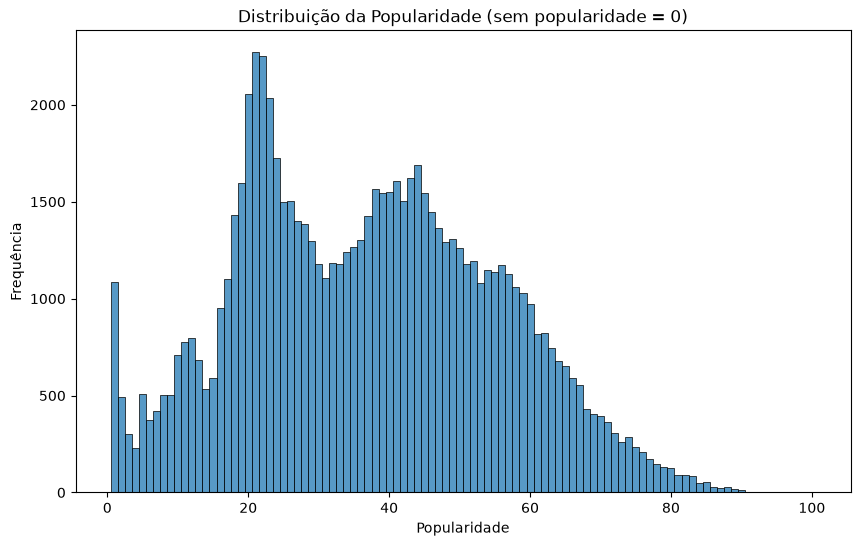

In [5]:
plt.figure(figsize=(10, 6))
sns.histplot(df[df['popularity'] > 0]['popularity'], discrete=True)

plt.title('Distribuição da Popularidade (sem popularidade = 0)')
plt.xlabel('Popularidade')
plt.ylabel('Frequência')
plt.show()

In [6]:
print(f'Faixas com popularidade = 0 removidas: {(df["popularity"] == 0).sum()}')

df = df[df['popularity'] > 0].reset_index(drop=True)
df_genero = df_genero[df_genero['popularity'] > 0].reset_index(drop=True)

print(f'Shape após remover popularidade = 0: {df.shape}')
print(df['popularity'].describe())

Faixas com popularidade = 0 removidas: 9443
Shape após remover popularidade = 0: (80135, 20)
count    80135.000000
mean        37.103363
std         18.136449
min          1.000000
25%         22.000000
50%         37.000000
75%         50.000000
max        100.000000
Name: popularity, dtype: float64


A popularidade tem um pico em zero, com cerca de 10% das faixas. O valor do Spotify depende do volume de reproduções recentes, então o zero aparece em lançamentos muito recentes, faixas com pouquíssimas reproduções, músicas antigas que não recebem plays atuais e álbuns de nicho, como ruído branco ou meditação. Nesses casos o zero não diz se a faixa é mais ou menos popular, só que não há dados de reprodução recente, e por isso removemos essas faixas. Isso é uma limitação: o modelo passa a valer apenas para faixas com alguma popularidade registrada.

Sem os zeros, a distribuição continua longe de uma normal. Ela tem dois picos, perto de 20 e de 40, e um pico menor em 1.

## Gêneros Musicais


 Quantidade de gêneros musicais do dataset:
 114


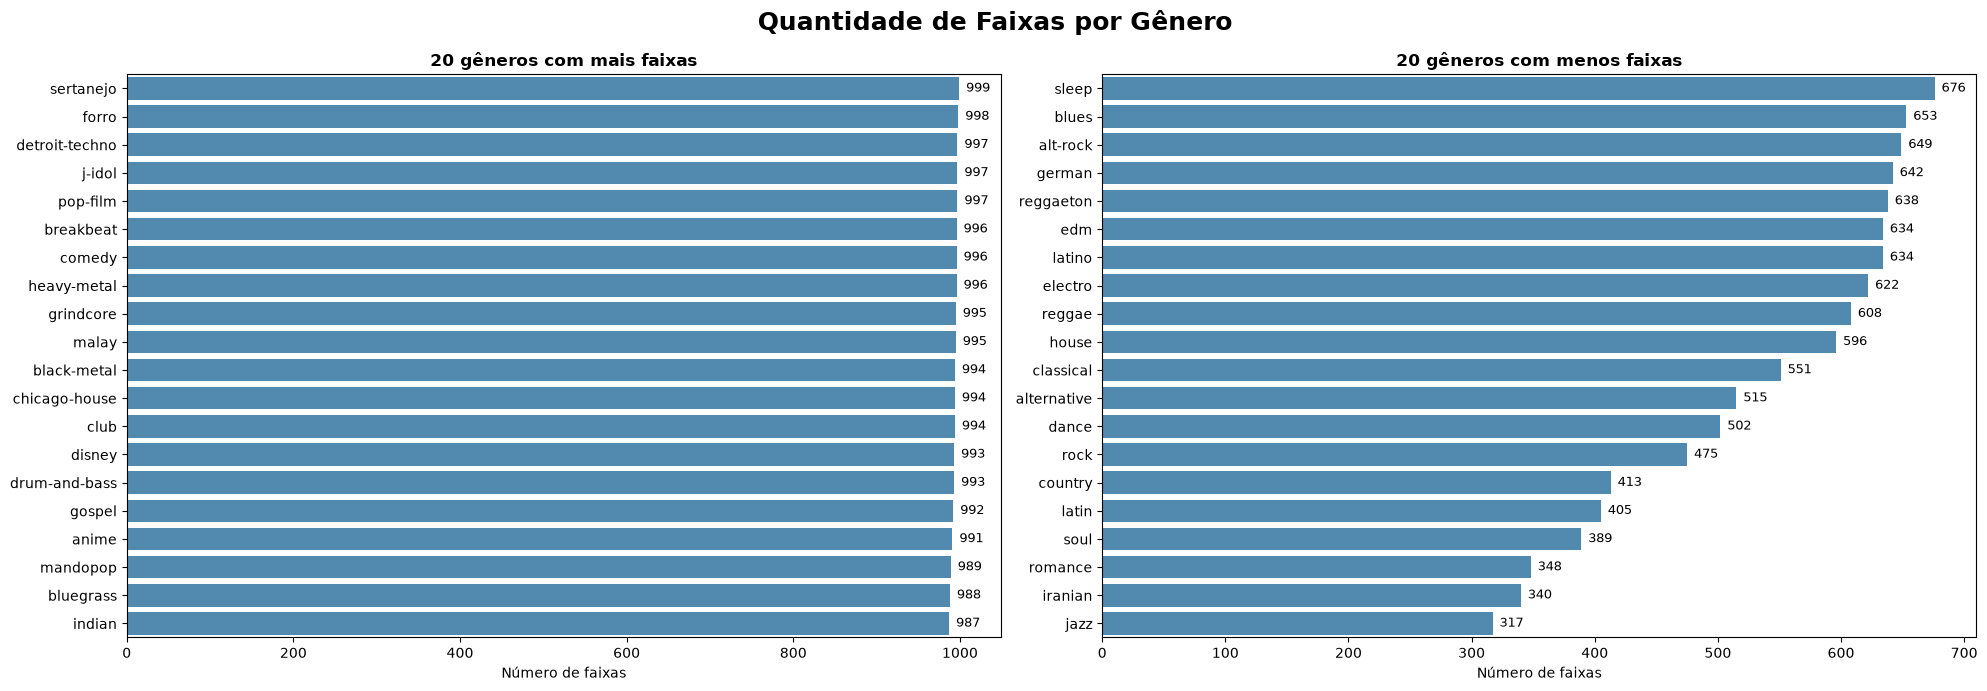

count    114.000000
mean     855.675439
std      173.778849
min      317.000000
25%      790.750000
50%      930.000000
75%      981.000000
max      999.000000
Name: count, dtype: float64


In [7]:
print(f'\n Quantidade de gêneros musicais do dataset:\n {df_genero["track_genre"].nunique()}')

contagem_genero = df_genero['track_genre'].value_counts()
top_contagem = contagem_genero.head(20)
bottom_contagem = contagem_genero.tail(20)

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
fig.suptitle('Quantidade de Faixas por Gênero', fontsize=18, fontweight='bold')

sns.barplot(ax=axes[0], x=top_contagem.values, y=top_contagem.index, alpha=0.85)
axes[0].set_title("20 gêneros com mais faixas", fontsize=12, fontweight='bold')

sns.barplot(ax=axes[1], x=bottom_contagem.values, y=bottom_contagem.index, alpha=0.85)
axes[1].set_title("20 gêneros com menos faixas", fontsize=12, fontweight='bold')

for ax in axes:
    ax.set_ylabel("")
    ax.set_xlabel("Número de faixas")
    if ax.containers:
        ax.bar_label(ax.containers[0], padding=5, fontsize=9)

plt.tight_layout()
plt.show()

print(contagem_genero.describe())

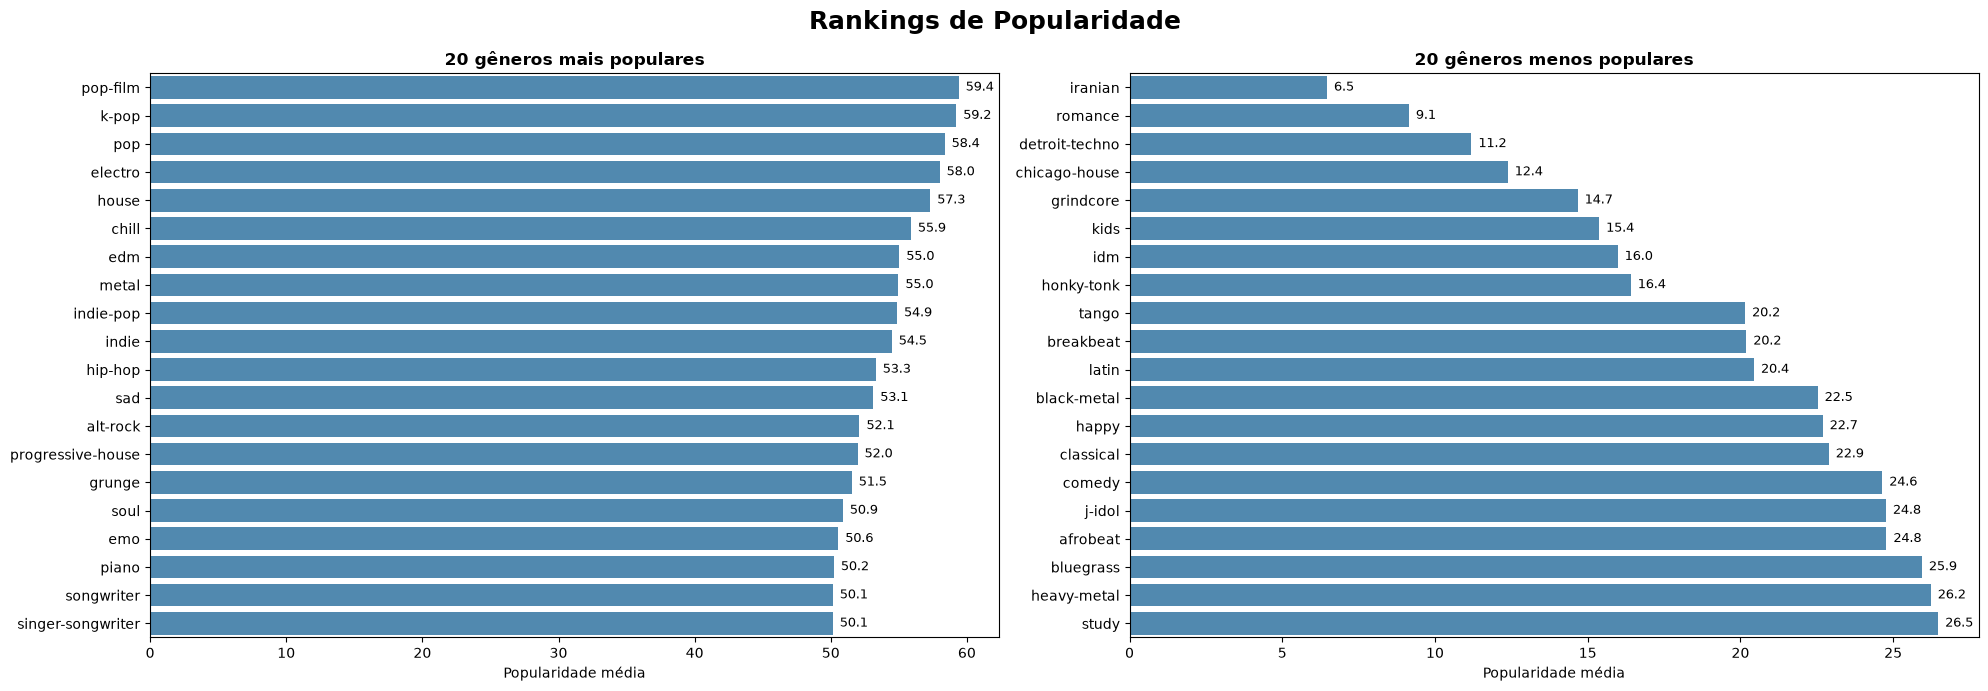

In [8]:
top_pop_genres = df_genero.groupby('track_genre')['popularity'].mean().sort_values(ascending=False).head(20)
bottom_pop_genres = df_genero.groupby('track_genre')['popularity'].mean().sort_values().head(20)

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
fig.suptitle('Rankings de Popularidade', fontsize=18, fontweight='bold')

sns.barplot(ax=axes[0], x=top_pop_genres.values, y=top_pop_genres.index, alpha=0.85)
axes[0].set_title("20 gêneros mais populares", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Popularidade média")

sns.barplot(ax=axes[1], x=bottom_pop_genres.values, y=bottom_pop_genres.index, alpha=0.85)
axes[1].set_title("20 gêneros menos populares", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Popularidade média")

for ax in axes:
    ax.set_ylabel("")
    if ax.containers:
        ax.bar_label(ax.containers[0], fmt='%.1f', padding=5, fontsize=9)

plt.tight_layout()
plt.show()

Na base original cada gênero tinha cerca de mil faixas. Os gráficos mostram a quantidade de faixas por gênero depois de todos os filtros e o ranking de popularidade média. A popularidade média muda bastante de um gênero para outro, o que sugere que o gênero tem relação com a popularidade.

Com 114 gêneros, usar essa variável direto no modelo geraria muitas variáveis dummy. Como cada faixa pode aparecer em mais de um gênero, o gênero também não entra no `df`. Esse ponto fica para a etapa de seleção de variáveis.

## Distribuições das Características Técnicas

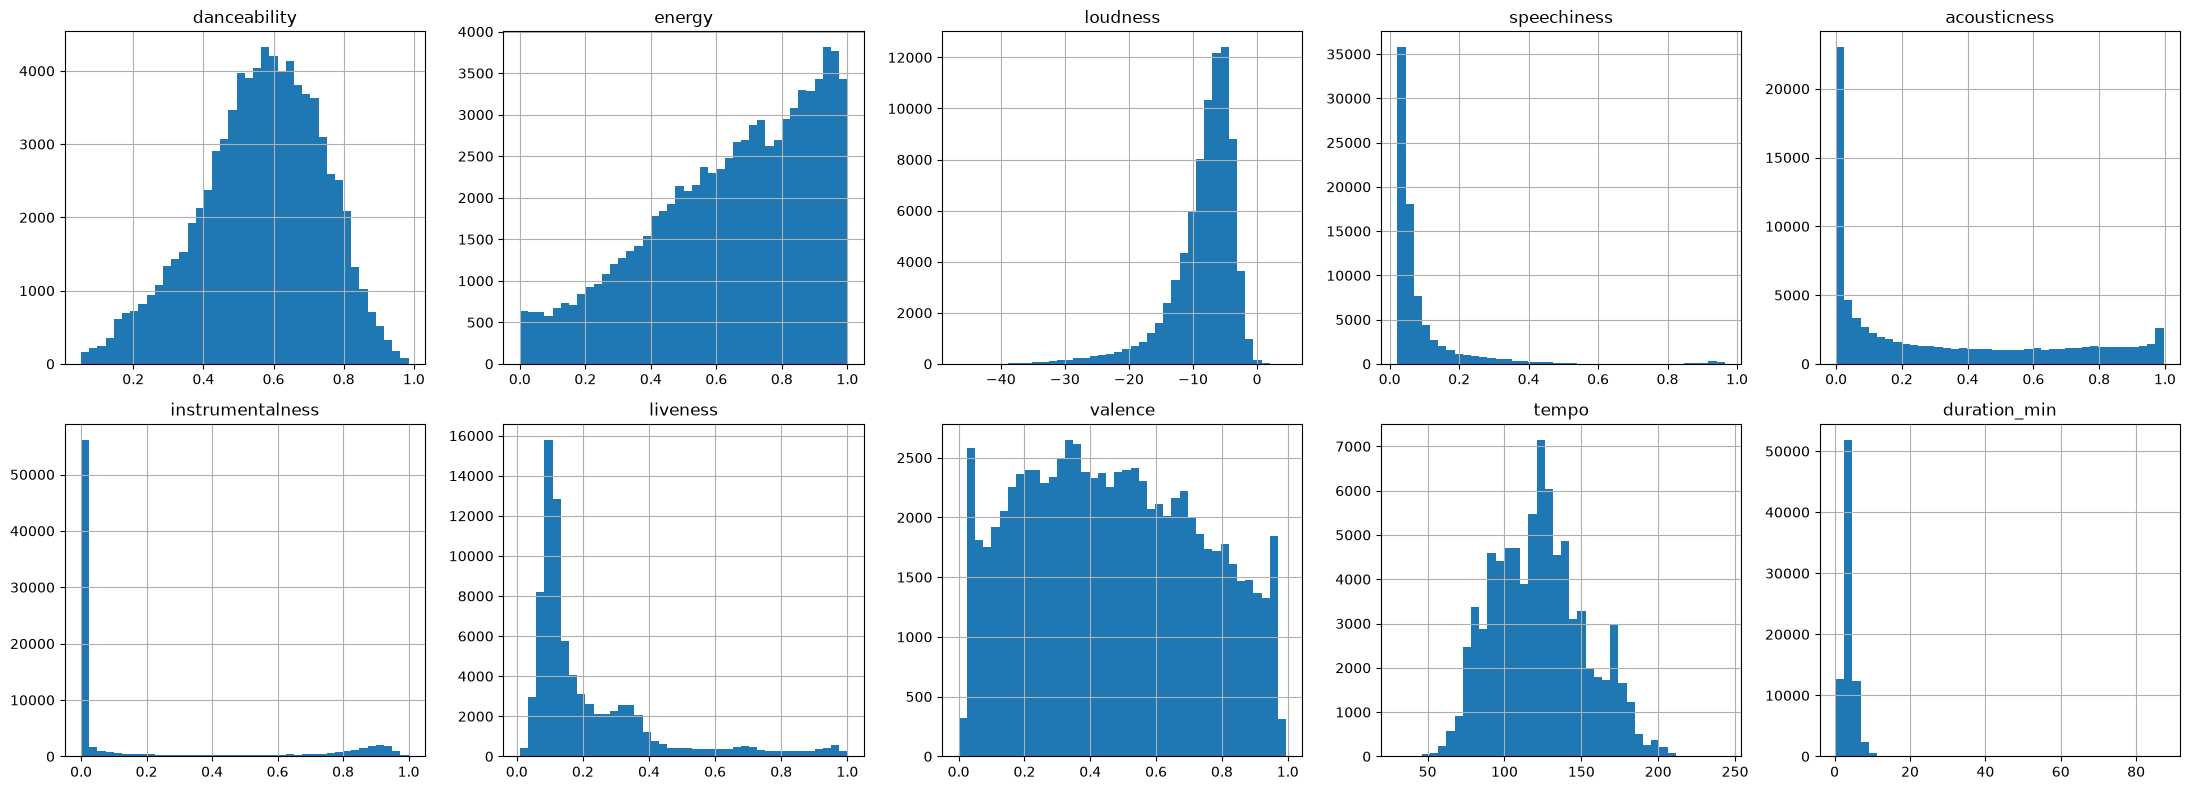

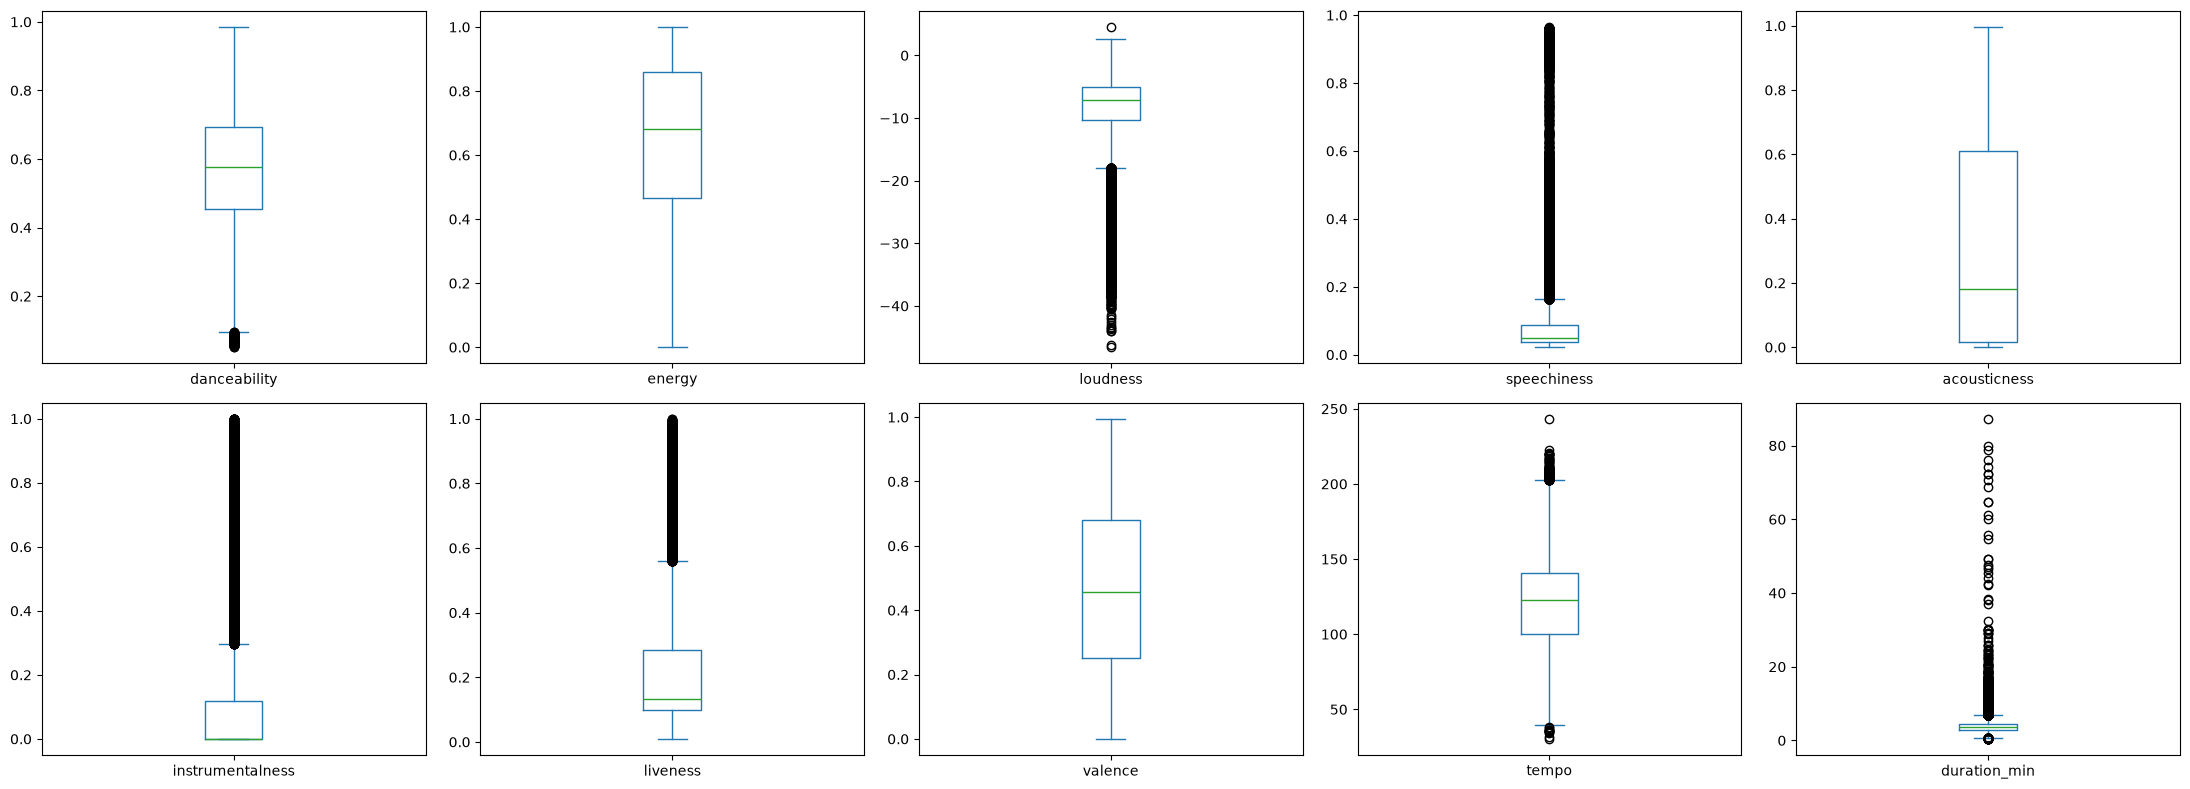

       danceability     energy   loudness  speechiness  acousticness  \
count     80135.000  80135.000  80135.000    80135.000     80135.000   
mean          0.564      0.642     -8.425        0.089         0.321   
std           0.174      0.253      5.104        0.117         0.334   
min           0.051      0.000    -46.591        0.022         0.000   
25%           0.453      0.467    -10.255        0.036         0.015   
50%           0.576      0.683     -7.186        0.049         0.181   
75%           0.692      0.858     -5.104        0.087         0.610   
max           0.985      1.000      4.532        0.965         0.996   

       instrumentalness   liveness    valence      tempo  duration_min  \
count         80135.000  80135.000  80135.000  80135.000     80135.000   
mean              0.178      0.220      0.469    122.712         3.850   
std               0.327      0.198      0.262     29.628         1.896   
min               0.000      0.009      0.000     30.32

In [9]:
df[caract_tec].hist(bins=40, figsize=(22, 8), layout=(2, 5))
plt.tight_layout()
plt.show()

df[caract_tec].plot(kind='box', subplots=True, layout=(2, 5), figsize=(22, 8))
plt.tight_layout()
plt.show()

print(df[caract_tec + ['popularity']].describe().round(3))
print(f'\nAssimetria:\n{df[caract_tec + ["popularity"]].skew().round(3)}')
print(f'\nTempo igual a 0: {(df["tempo"] == 0).sum()}')
print(f'Duração acima de 10 min: {(df["duration_min"] > 10).sum()}')

Os histogramas e boxplots mostram que várias características são bem assimétricas. A duration_min é a mais extrema, com poucas faixas muito longas (algumas passam de 10 minutos) esticando a cauda para a direita. A loudness tem cauda longa para a esquerda. Speechiness, liveness e instrumentalness ficam concentradas perto de zero, com cauda para a direita, e a acousticness tem picos em 0 e em 1. Danceability, valence e tempo estão razoavelmente simétricas e a energy tem uma leve assimetria à esquerda. Também há faixas com tempo igual a 0, que mantivemos.

# Transformação das Variáveis Assimétricas

In [10]:
print(f'Mínimo de duration_min: {df["duration_min"].min():.4f}')
print(f'Máximo de loudness: {df["loudness"].max():.2f}')

loud_refl = df['loudness'].max() + 1 - df['loudness']

for nome, serie in [('duration_min', df['duration_min']), ('loudness refletida', loud_refl)]:
    print(f'\n{nome}')
    for l in [-1, -0.5, 0, 0.5, 1, 2]:
        print(f'lambda = {l}: assimetria = {pd.Series(stats.boxcox(serie, lmbda=l)).skew():.3f}')

Mínimo de duration_min: 0.4044
Máximo de loudness: 4.53

duration_min
lambda = -1: assimetria = -3.660
lambda = -0.5: assimetria = -1.804
lambda = 0: assimetria = -0.342
lambda = 0.5: assimetria = 1.809
lambda = 1: assimetria = 11.195
lambda = 2: assimetria = 62.322

loudness refletida
lambda = -1: assimetria = -1.129
lambda = -0.5: assimetria = 0.088
lambda = 0: assimetria = 0.681
lambda = 0.5: assimetria = 1.274
lambda = 1: assimetria = 1.952
lambda = 2: assimetria = 3.664


In [11]:
eps = 1e-3

df['duration_log'] = np.log(df['duration_min'])
df['loudness_bc'], lambda_loudness = stats.boxcox(loud_refl)
print(f'lambda loudness (refletida): {lambda_loudness:.3f}')

escolhas = {}
linhas = []
for c in ['speechiness', 'liveness']:
    z = df[c].where(df[c] > 0, eps)
    zl = z.where(z < 1, 1 - eps)
    df[c + '_logit'] = np.log(zl / (1 - zl))
    df[c + '_bc'], lam = stats.boxcox(z)
    opcoes = {'original': df[c], 'logito': df[c + '_logit'], 'box-cox': df[c + '_bc']}
    melhor = min(opcoes, key=lambda k: abs(opcoes[k].skew()))
    df[c + '_t'] = opcoes[melhor]
    escolhas[c] = melhor
    linhas.append([c, df[c].skew(), df[c + '_logit'].skew(), df[c + '_bc'].skew(), lam, melhor])

comparacao_sl = pd.DataFrame(linhas, columns=['variavel', 'original', 'logito', 'box-cox', 'lambda', 'escolhida']).set_index('variavel')
print(comparacao_sl.round(3))

lambda loudness (refletida): -0.605
             original  logito  box-cox  lambda escolhida
variavel                                                
speechiness     4.489   2.386    0.227  -0.816   box-cox
liveness        2.031   1.761    0.021  -0.298   box-cox


In [12]:
df['instrumental'] = np.where(df['instrumentalness'] > 0.5, 'Instrumental', 'Não instrumental')

tabela_inst = df['instrumental'].value_counts().to_frame('n')
tabela_inst['%'] = (tabela_inst['n'] / tabela_inst['n'].sum() * 100).round(2)
print(tabela_inst)
print(df.groupby('instrumental')['popularity'].agg(['mean', 'median', 'count']).round(2))

                      n      %
instrumental                  
Não instrumental  64887  80.97
Instrumental      15248  19.03
                   mean  median  count
instrumental                          
Instrumental      30.26    26.0  15248
Não instrumental  38.71    38.0  64887


              original  transformada
duration_min    11.195        -0.342
loudness        -1.952        -0.063
speechiness      4.489         0.227
liveness         2.031         0.021


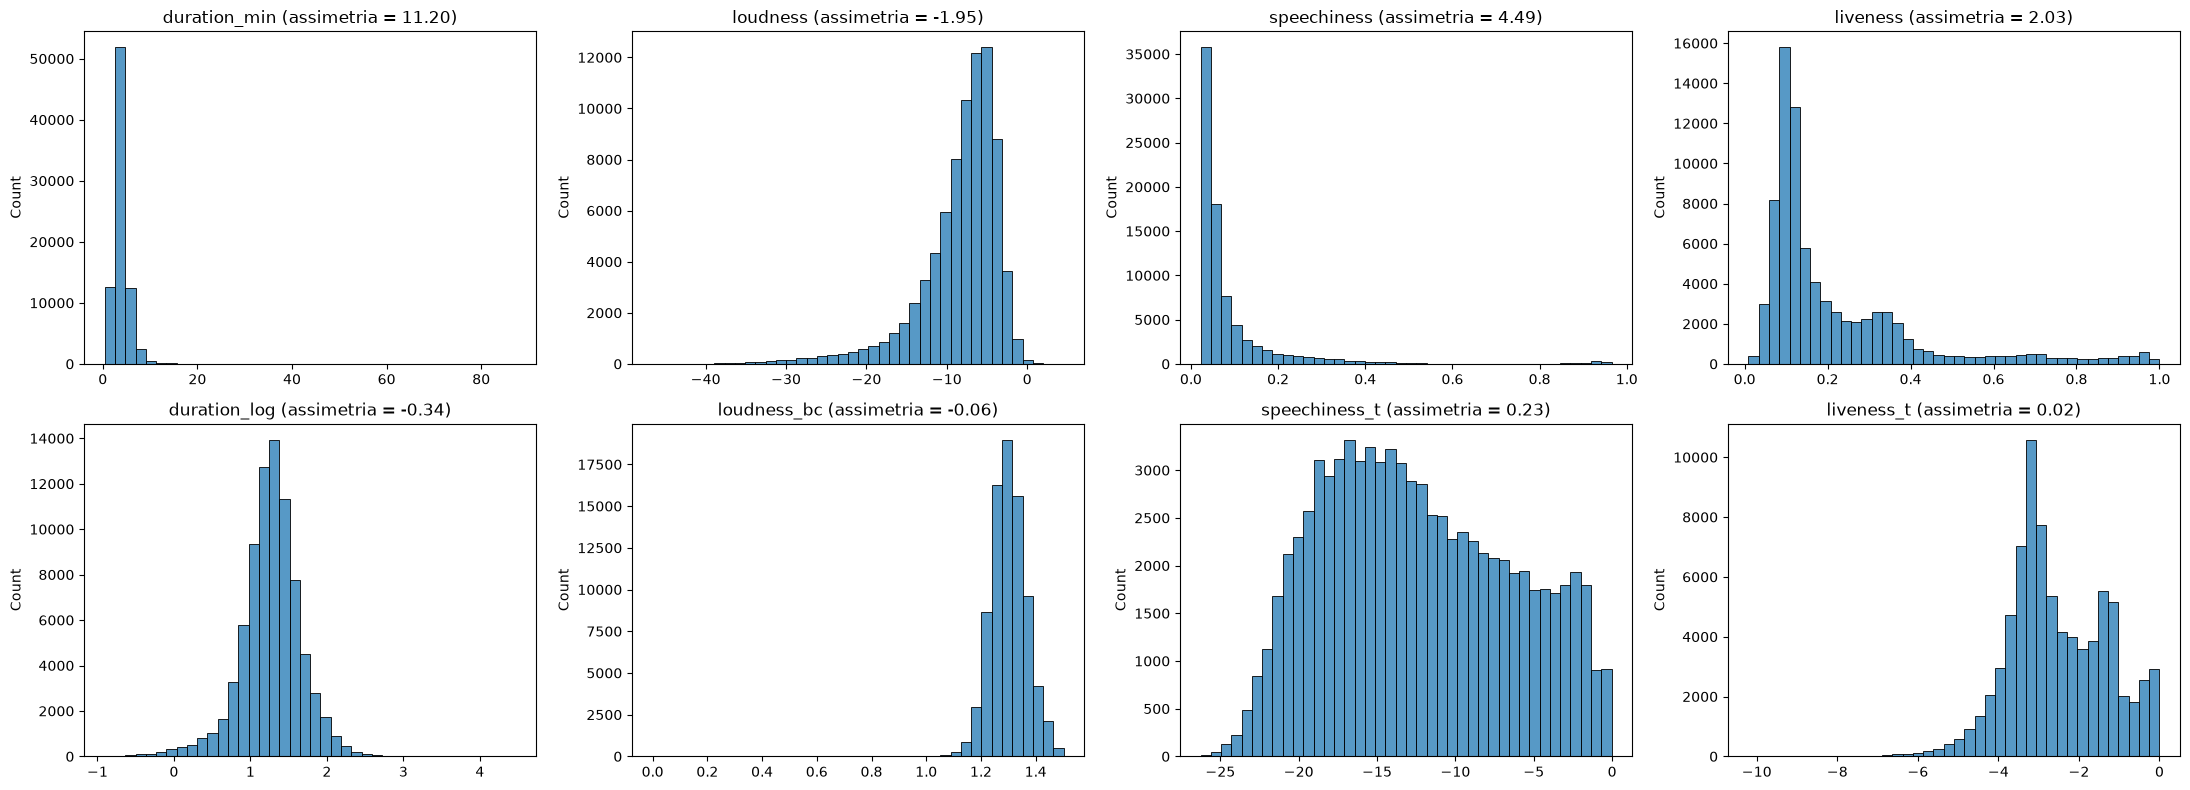

In [13]:
pares = {
    'duration_min': 'duration_log',
    'loudness': 'loudness_bc',
    'speechiness': 'speechiness_t',
    'liveness': 'liveness_t'
}

comparacao = pd.DataFrame({
    'original': [df[o].skew() for o in pares],
    'transformada': [df[t].skew() for t in pares.values()]
}, index=list(pares.keys())).round(3)
print(comparacao)

fig, axes = plt.subplots(2, len(pares), figsize=(22, 8))
for i, (o, t) in enumerate(pares.items()):
    sns.histplot(df[o], bins=40, ax=axes[0, i])
    sns.histplot(df[t], bins=40, ax=axes[1, i])
    axes[0, i].set_title(f'{o} (assimetria = {df[o].skew():.2f})')
    axes[1, i].set_title(f'{t} (assimetria = {df[t].skew():.2f})')
    axes[0, i].set_xlabel('')
    axes[1, i].set_xlabel('')
plt.tight_layout()
plt.show()

Para as variáveis assimétricas usamos as transformações do enunciado. A duration_min recebeu log (Box-Cox com λ = 0): o λ ótimo estimado ficou perto de zero e o log é mais fácil de interpretar. A loudness é negativa, então a refletimos (máximo + 1 − loudness) para deixá-la positiva e aplicamos Box-Cox com o λ estimado. Por causa da reflexão, o sinal das relações se inverte: valores maiores de loudness_bc correspondem a faixas menos altas. Com isso, duration_min e loudness, que eram as mais assimétricas, ficaram praticamente simétricas.

Em speechiness e liveness comparamos a variável original, o logito e o Box-Cox direto, e ficamos com a opção de menor assimetria em módulo (tabela acima). Os valores iguais a 0 foram trocados por 10⁻³, porque o logito e o Box-Cox só valem para valores positivos.

Na acousticness o logito só inverteu o sinal da assimetria, sem melhora. A variável tem picos nas duas pontas (0 e 1) em vez de uma cauda, então mantivemos a original. A instrumentalness é bimodal, com a maior parte das faixas perto de 0 e outro grupo perto de 0,9, e nenhuma transformação resolve isso. Por isso a transformamos em uma variável categórica (instrumental quando o valor é maior que 0,5, que é o limite indicado na documentação do Spotify).

# Caracterização das Variáveis após o Tratamento

## Distribuições

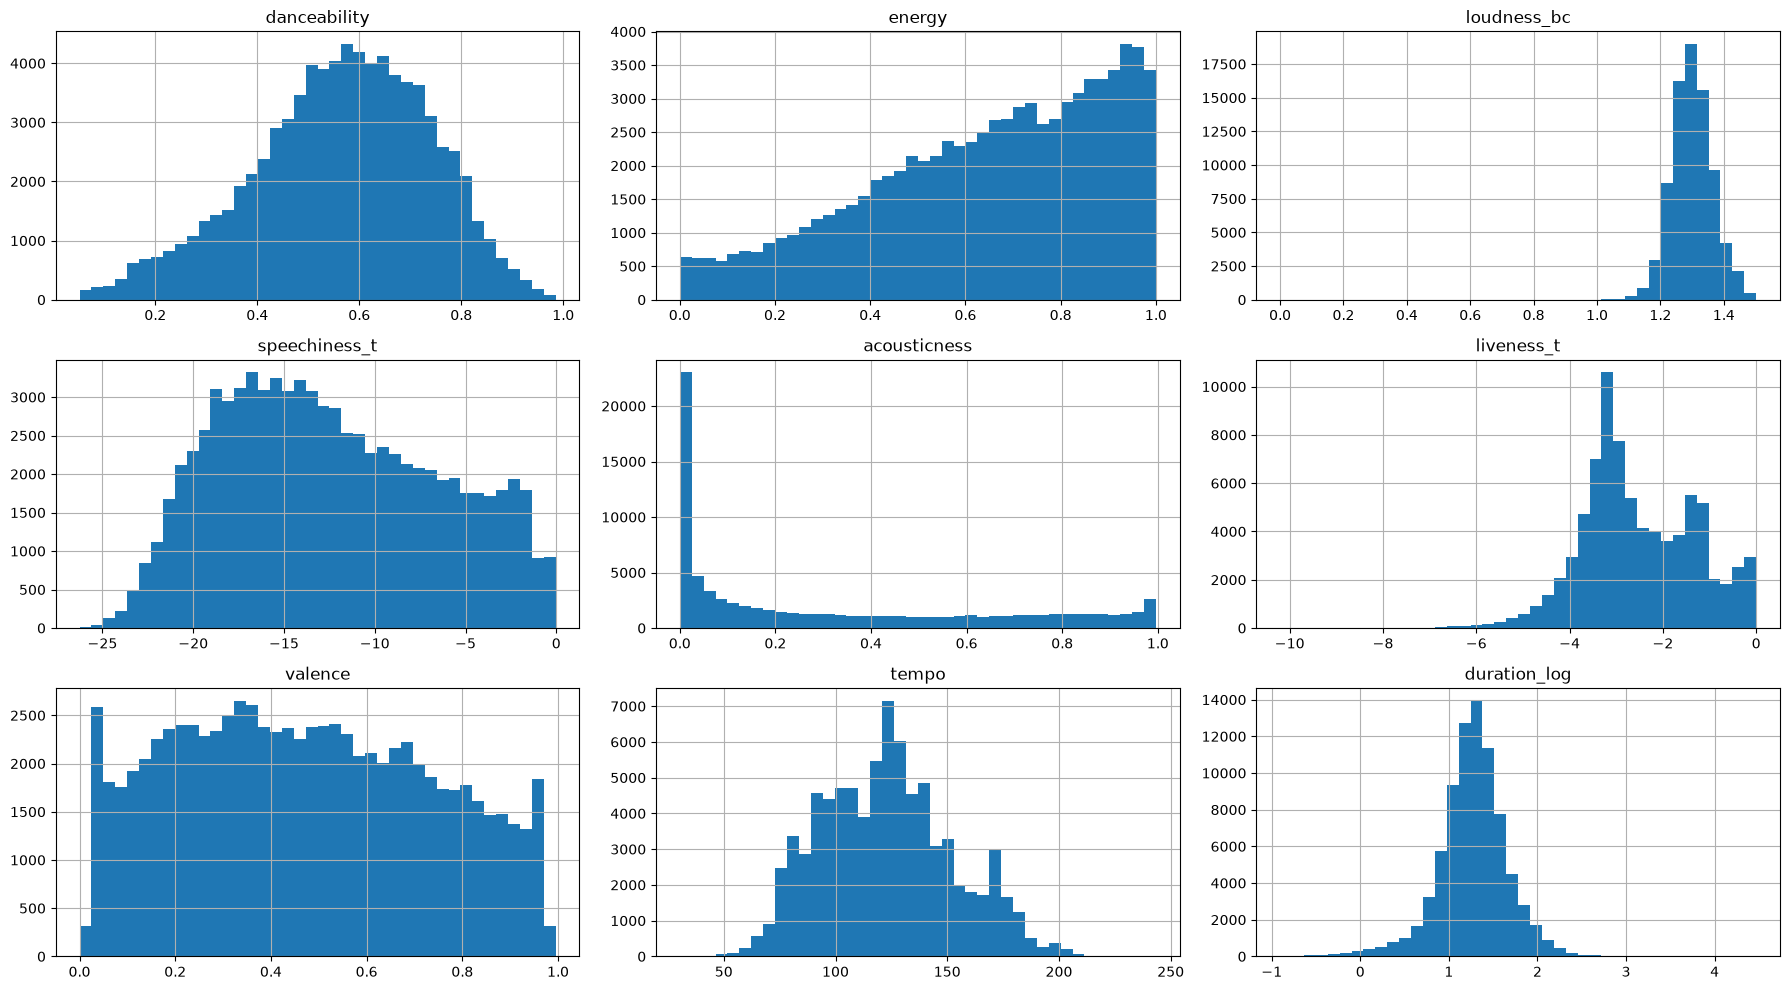

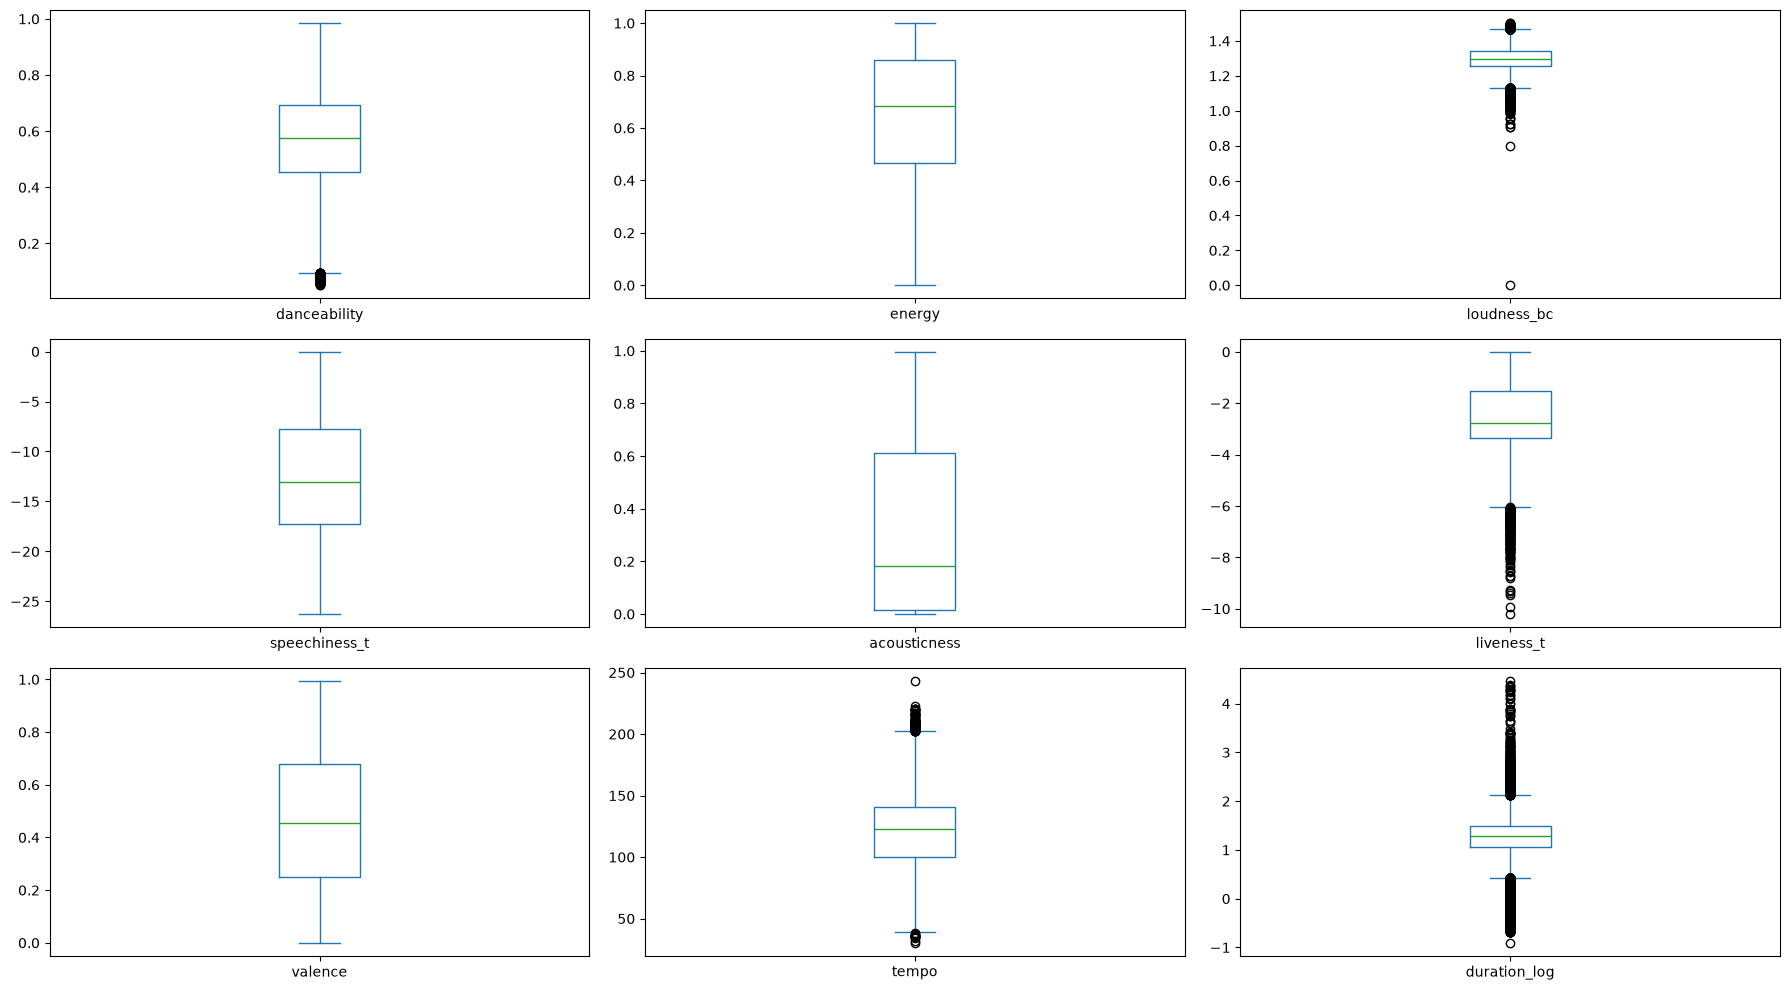

       danceability     energy  loudness_bc  speechiness_t  acousticness  \
count     80135.000  80135.000    80135.000      80135.000     80135.000   
mean          0.564      0.642        1.300        -12.420         0.321   
std           0.174      0.253        0.064          5.956         0.334   
min           0.051      0.000        0.000        -26.261         0.000   
25%           0.453      0.467        1.258        -17.235         0.015   
50%           0.576      0.683        1.298        -13.082         0.181   
75%           0.692      0.858        1.342         -7.736         0.610   
max           0.985      1.000        1.502         -0.036         0.996   

       liveness_t    valence      tempo  duration_log  popularity  
count   80135.000  80135.000  80135.000     80135.000   80135.000  
mean       -2.535      0.469    122.712         1.269      37.103  
std         1.219      0.262     29.628         0.399      18.136  
min       -10.205      0.000     30.322    

In [14]:
caract_final = [
    'danceability','energy','loudness_bc','speechiness_t','acousticness',
    'liveness_t','valence','tempo','duration_log'
]

df[caract_final].hist(bins=40, figsize=(18, 10), layout=(3, 3))
plt.tight_layout()
plt.show()

df[caract_final].plot(kind='box', subplots=True, layout=(3, 3), figsize=(18, 10))
plt.tight_layout()
plt.show()

print(df[caract_final + ['popularity']].describe().round(3))
print(f'\nAssimetria:\n{df[caract_final + ["popularity"]].skew().round(3)}')

As distribuições finais são bem mais simétricas que as originais. Alguns boxplots ainda mostram pontos fora do padrão, como o tempo, por causa das faixas com tempo igual a 0, mas não fizemos nenhuma remoção além das já descritas.

## Scatterplot Matrix

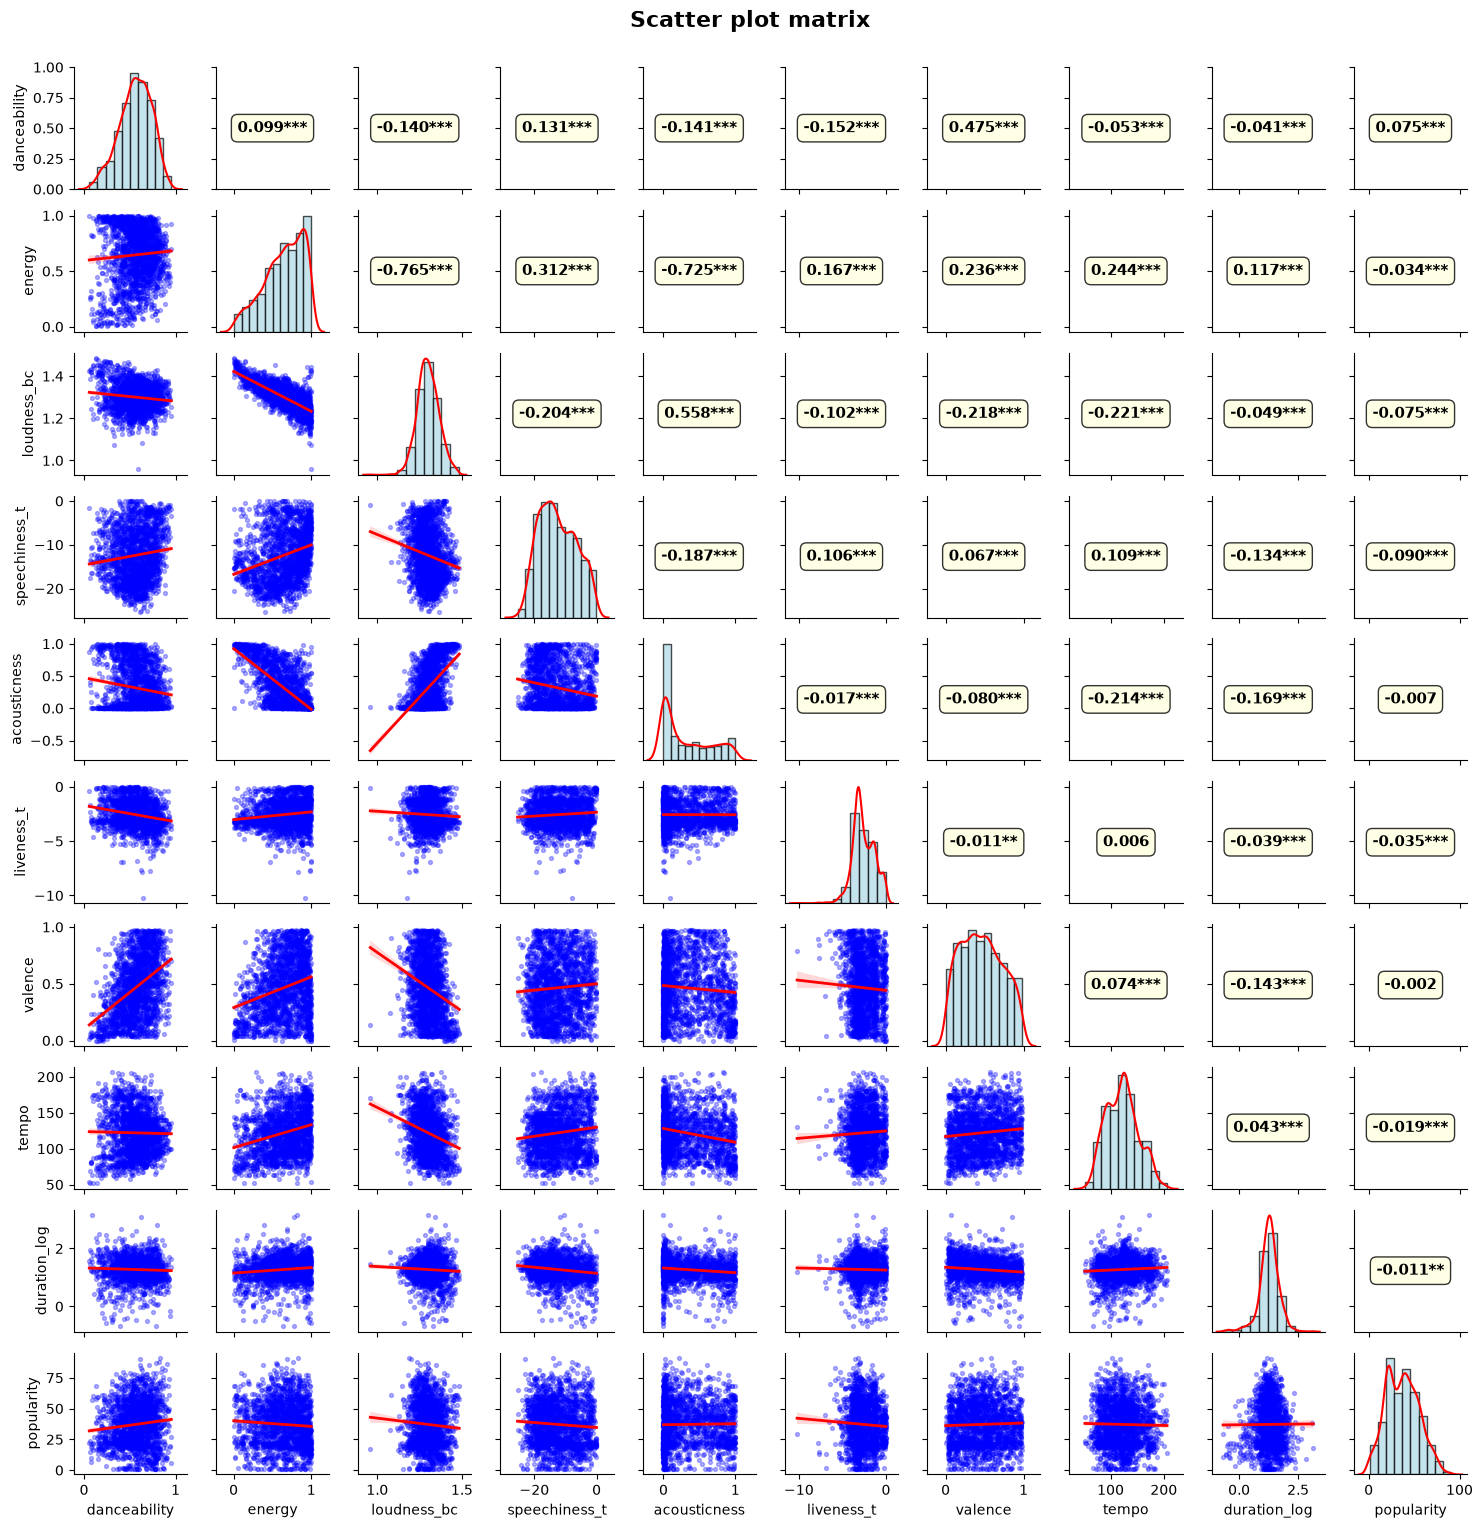

In [15]:
def pairs_panels_python(data, vars_list=None, n_amostra=2000, height=1.5):
    if vars_list is None:
        vars_list = data.columns.tolist()

    completo = data[vars_list]
    amostra = completo.sample(min(n_amostra, len(completo)), random_state=42)

    g = sns.PairGrid(amostra, diag_sharey=False, height=height)

    g.map_diag(plt.hist, alpha=0.7, density=True, color='lightblue', edgecolor='black')
    g.map_diag(sns.kdeplot, color='red', linewidth=1.5)

    g.map_lower(sns.regplot,
                scatter_kws={'alpha': 0.3, 's': 8, 'color': 'blue'},
                line_kws={'color': 'red', 'linewidth': 2},
                ci=95)

    def corr_with_stars(x, y, **kws):
        from scipy.stats import pearsonr

        r, p_value = pearsonr(completo[x.name], completo[y.name])

        if p_value < 0.001:
            stars = '***'
        elif p_value < 0.01:
            stars = '**'
        elif p_value < 0.05:
            stars = '*'
        else:
            stars = ''

        ax = plt.gca()
        ax.annotate(f'{r:.3f}{stars}',
                    xy=(0.5, 0.5), xycoords=ax.transAxes,
                    horizontalalignment='center',
                    verticalalignment='center',
                    fontsize=11, weight='bold', color='black',
                    bbox=dict(boxstyle="round,pad=0.4", facecolor="lightyellow", alpha=0.8))

    g.map_upper(corr_with_stars)

    g.figure.suptitle('Scatter plot matrix', y=1.02, fontsize=16, fontweight='bold')

    return g

g = pairs_panels_python(df, caract_final + ['popularity'])
plt.show()

A scatterplot matrix usa a função do material da disciplina: histograma com densidade na diagonal, dispersão com reta de regressão e intervalo de confiança abaixo e correlação de Pearson com asteriscos acima. Para não pesar, as dispersões usam uma amostra aleatória de 2.000 faixas, mas as correlações foram calculadas com todas elas.

As correlações das variáveis com a popularidade são todas fracas, então esperamos um R² baixo no modelo. Entre as variáveis explicativas, as maiores correlações aparecem entre energy e loudness_bc e entre energy e acousticness, o que pode gerar multicolinearidade na seleção de variáveis. Como são muitas faixas, até correlações pequenas aparecem com ***, então vale olhar o valor da correlação e não só os asteriscos.

## Popularidade vs Características Técnicas

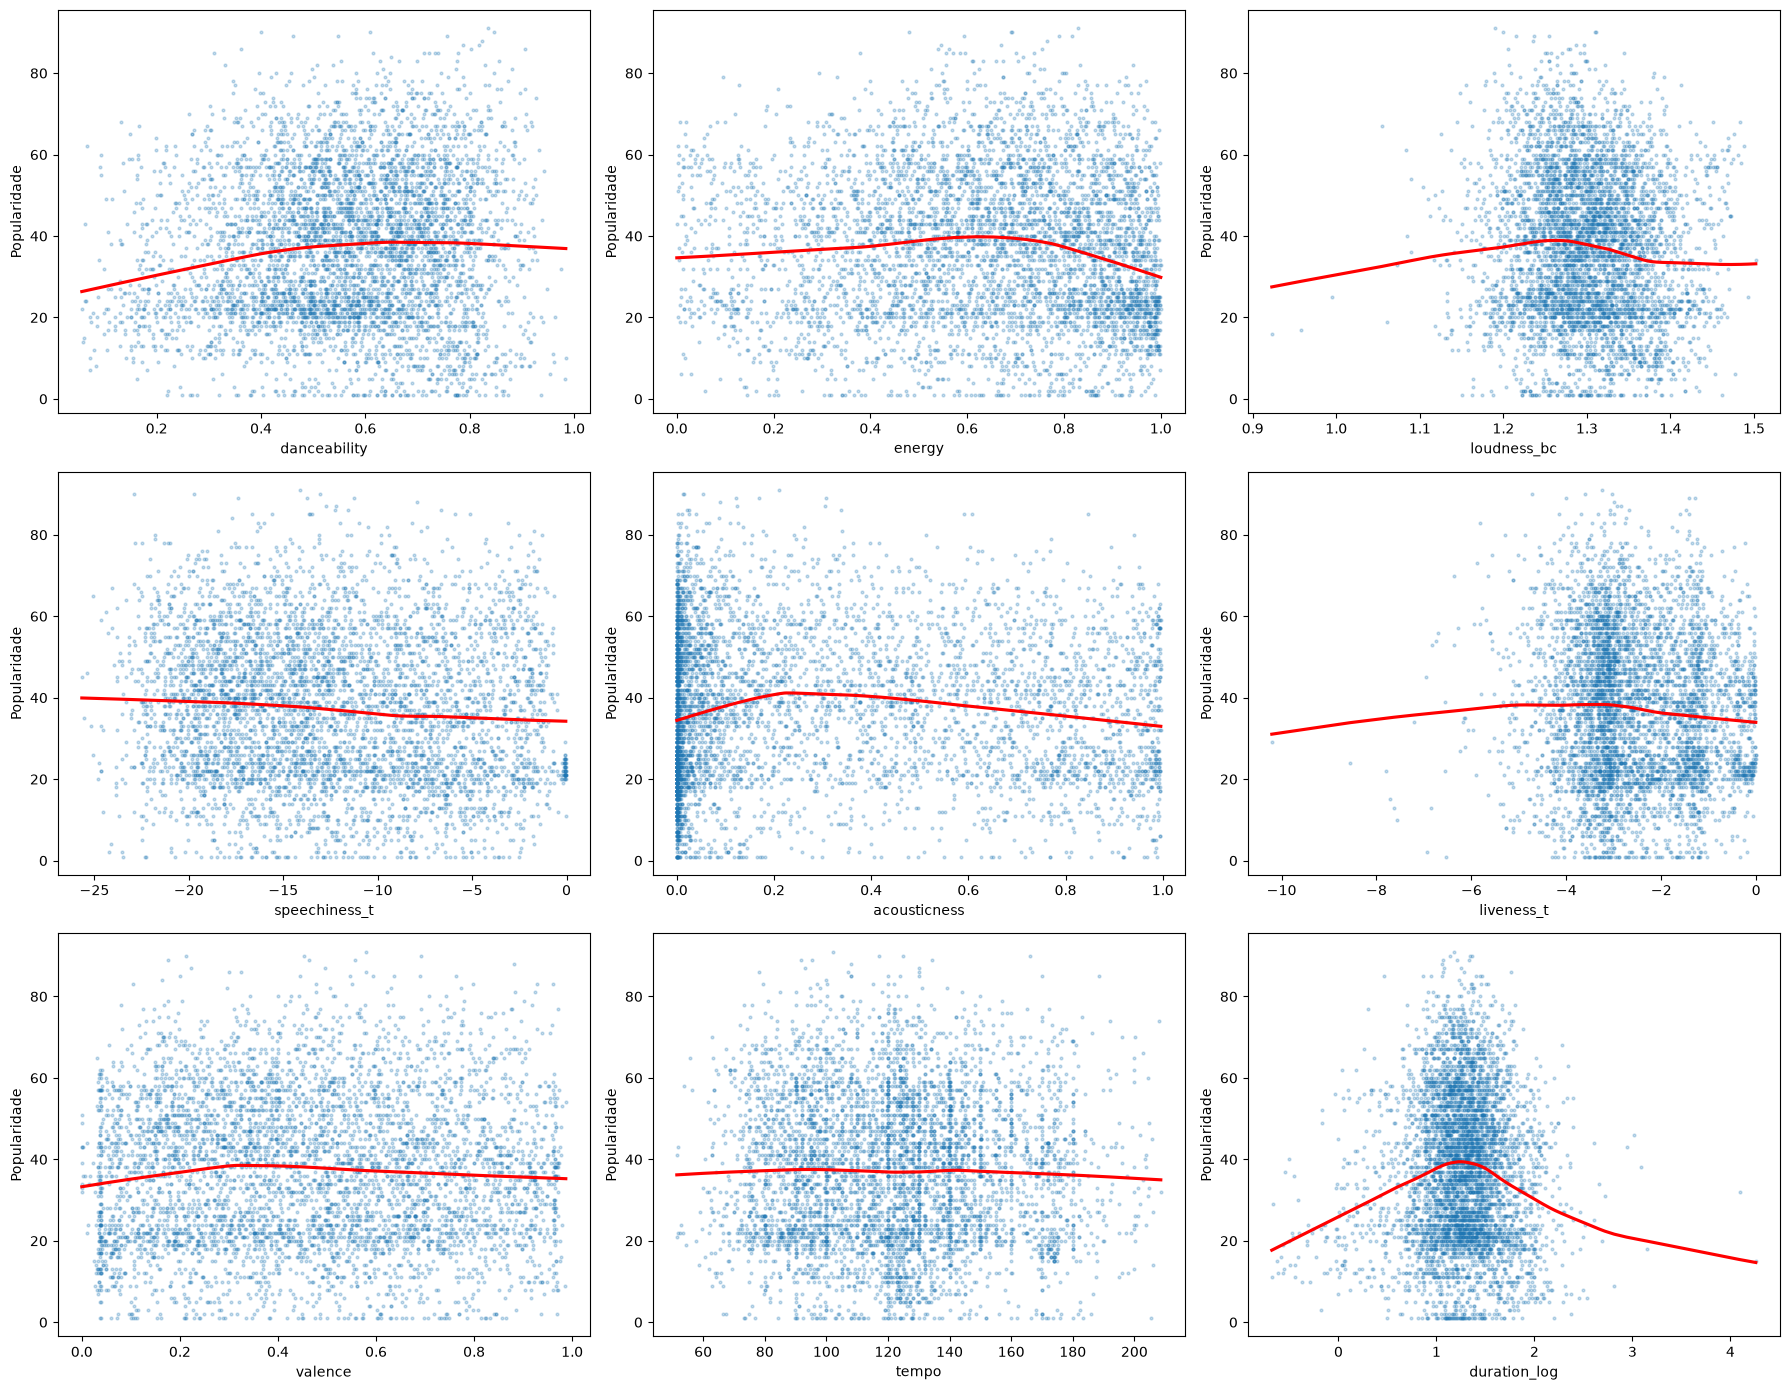

In [16]:
amostra_lowess = df.sample(5000, random_state=42)

fig, axes = plt.subplots(3, 3, figsize=(18, 14))

for ax, c in zip(axes.flat, caract_final):
    sns.regplot(data=amostra_lowess, x=c, y='popularity', lowess=True,
                scatter_kws={'s': 4, 'alpha': 0.25}, line_kws={'color': 'red'}, ax=ax)
    ax.set_ylabel('Popularidade')

plt.tight_layout()
plt.show()

Os gráficos de popularidade contra cada variável mostram relações fracas. Em algumas variáveis, como danceability, energy e acousticness, a curva suavizada não é uma reta, o que pode ser um problema para a premissa de linearidade do modelo.

## Variáveis Categóricas

In [17]:
for col in ['explicita', 'modo', 'nota', 'compasso', 'instrumental']:
    tabela = df[col].value_counts().to_frame('n')
    tabela['%'] = (tabela['n'] / tabela['n'].sum() * 100).round(2)
    tabela.index.name = None
    print(f'\n{col}')
    print(tabela)


explicita
                   n      %
Não explícita  73202  91.35
Explícita       6933   8.65

modo
           n      %
Maior  50801  63.39
Menor  29334  36.61

nota
          n      %
G      9496  11.85
C      9123  11.38
D      8454  10.55
A      8051  10.05
C♯/D♭  7638   9.53
E      6512   8.13
F      6425   8.02
B      6411   8.00
F♯/G♭  5476   6.83
A♯/B♭  5220   6.51
G♯/A♭  4909   6.13
D♯/E♭  2420   3.02

compasso
         n      %
4/4  71520  89.25
3/4   6513   8.13
5/4   1365   1.70
1/4    737   0.92

instrumental
                      n      %
Não instrumental  64887  80.97
Instrumental      15248  19.03


O compasso é a variável com categorias mais desiguais: o 4/4 concentra quase 90% das faixas, o 3/4 fica perto de 8% e o 1/4 e o 5/4 ficam abaixo de 2% cada. Mantivemos todas as categorias porque elas não são equivalentes entre si e ainda têm faixas suficientes para estimar um coeficiente. A explicit também é desbalanceada, com cerca de 9% de faixas explícitas. Na nota, a D♯/E♭ é a menos frequente, com cerca de 3%. A tabela de instrumental mostra a proporção dos dois grupos criados a partir da instrumentalness.

## Popularidade de músicas Explícitas vs Não-Explícitas

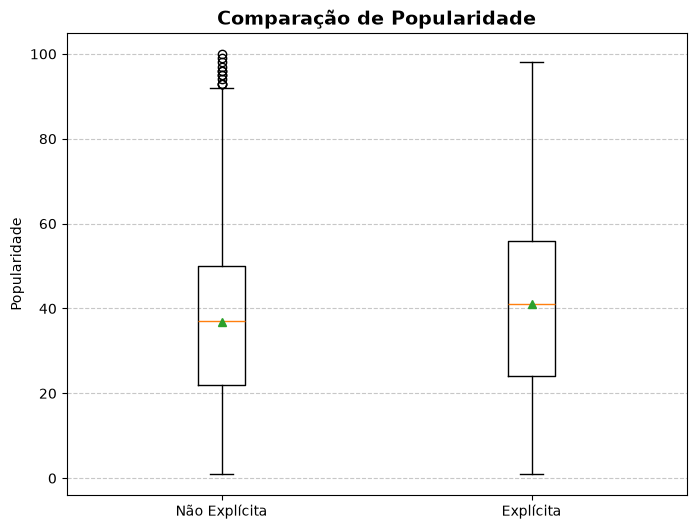

Não explícitas: 73202 | média = 36.74
Explícitas: 6933 | média = 40.99


In [18]:
df_explicit = df[df["explicit"] == 1]["popularity"]
df_non_explicit = df[df["explicit"] == 0]["popularity"]

plt.figure(figsize=(8, 6))
plt.boxplot([df_non_explicit, df_explicit], tick_labels=["Não Explícita", "Explícita"], showmeans=True)

plt.title("Comparação de Popularidade", fontsize=14, fontweight="bold")
plt.ylabel("Popularidade")
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()

print(f'Não explícitas: {len(df_non_explicit)} | média = {df_non_explicit.mean():.2f}')
print(f'Explícitas: {len(df_explicit)} | média = {df_explicit.mean():.2f}')

## Popularidade vs Nota Musical

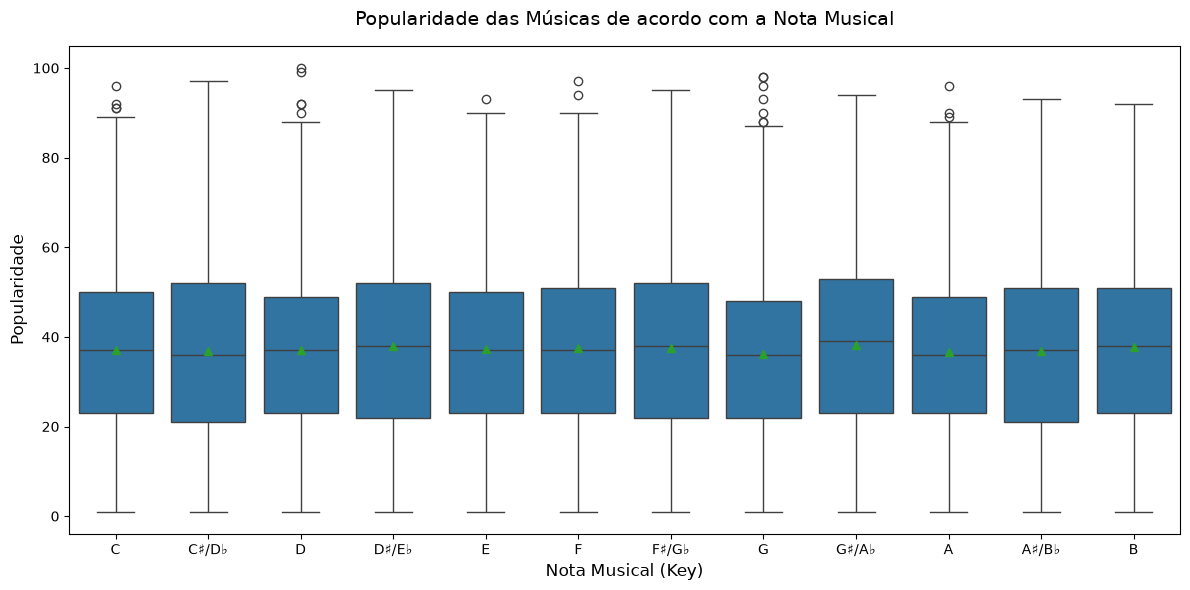

        mean  median  count
nota                       
C      37.06    37.0   9123
C♯/D♭  36.75    36.0   7638
D      37.07    37.0   8454
D♯/E♭  37.96    38.0   2420
E      37.29    37.0   6512
F      37.47    37.0   6425
F♯/G♭  37.48    38.0   5476
G      36.20    36.0   9496
G♯/A♭  38.25    39.0   4909
A      36.69    36.0   8051
A♯/B♭  36.82    37.0   5220
B      37.63    38.0   6411


In [19]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='nota', y='popularity', order=key_names, showmeans=True)

plt.title('Popularidade das Músicas de acordo com a Nota Musical', fontsize=14, pad=15)
plt.xlabel('Nota Musical (Key)', fontsize=12)
plt.ylabel('Popularidade', fontsize=12)

plt.tight_layout()
plt.show()

print(df.groupby('nota')['popularity'].agg(['mean', 'median', 'count']).loc[key_names].round(2))

## Popularidade Vs Modo

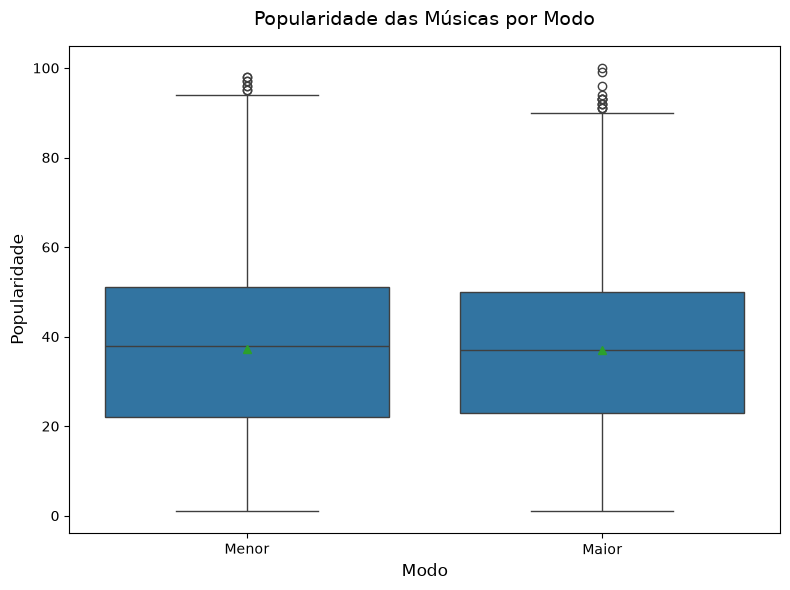

        mean  median  count
modo                       
Maior  36.99    37.0  50801
Menor  37.30    38.0  29334


In [20]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='modo', y='popularity', order=['Menor', 'Maior'], showmeans=True)

plt.title('Popularidade das Músicas por Modo', fontsize=14, pad=15)
plt.xlabel('Modo', fontsize=12)
plt.ylabel('Popularidade', fontsize=12)

plt.tight_layout()
plt.show()

print(df.groupby('modo')['popularity'].agg(['mean', 'median', 'count']).round(2))

## Popularidade vs Compasso

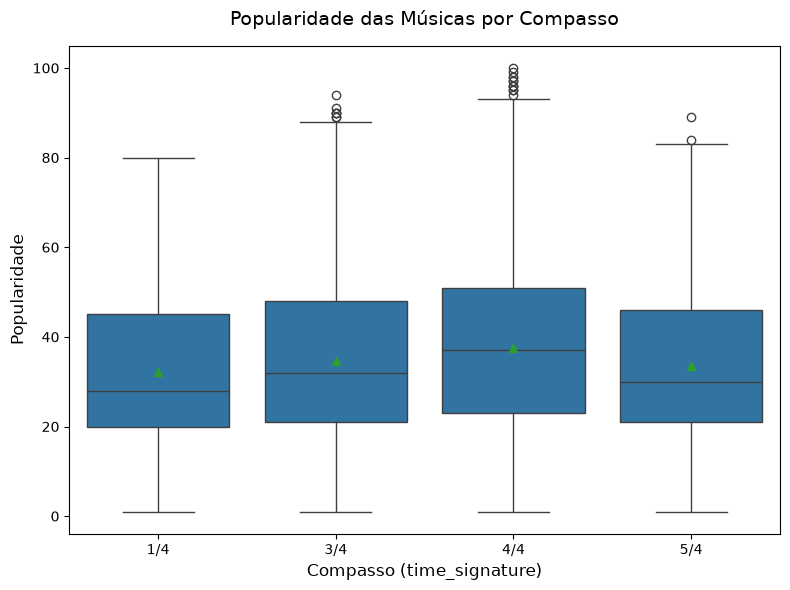

           mean  median  count
compasso                      
1/4       32.27    28.0    737
3/4       34.55    32.0   6513
4/4       37.46    37.0  71520
5/4       33.43    30.0   1365


In [21]:
ordem_compasso = sorted(df['compasso'].unique())

plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='compasso', y='popularity', order=ordem_compasso, showmeans=True)

plt.title('Popularidade das Músicas por Compasso', fontsize=14, pad=15)
plt.xlabel('Compasso (time_signature)', fontsize=12)
plt.ylabel('Popularidade', fontsize=12)

plt.tight_layout()
plt.show()

print(df.groupby('compasso')['popularity'].agg(['mean', 'median', 'count']).round(2))

## Popularidade vs Instrumental

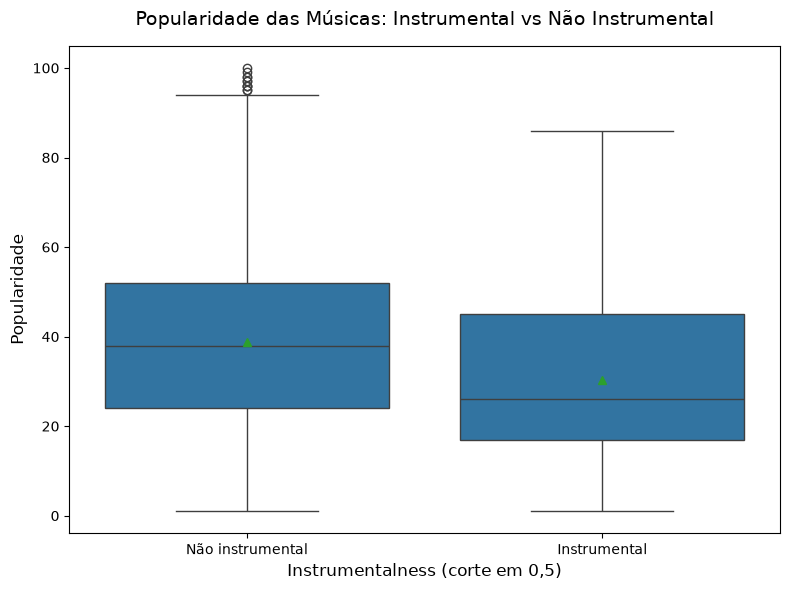

                   mean  median  count
instrumental                          
Instrumental      30.26    26.0  15248
Não instrumental  38.71    38.0  64887


In [22]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='instrumental', y='popularity', order=['Não instrumental', 'Instrumental'], showmeans=True)

plt.title('Popularidade das Músicas: Instrumental vs Não Instrumental', fontsize=14, pad=15)
plt.xlabel('Instrumentalness (corte em 0,5)', fontsize=12)
plt.ylabel('Popularidade', fontsize=12)

plt.tight_layout()
plt.show()

print(df.groupby('instrumental')['popularity'].agg(['mean', 'median', 'count']).round(2))

As médias de popularidade por nota e por modo são muito parecidas entre as categorias e as caixas se sobrepõem quase por completo, então essas variáveis devem ter pouco poder explicativo. Faixas explícitas têm média um pouco maior que as não explícitas. No compasso, o 4/4 tem média maior que as demais categorias. Para instrumental, a comparação entre os dois grupos está no gráfico e na tabela acima.